# Sampling

## Setup

In [1]:
from pyDOE import lhs
from smt.sampling_methods import LHS
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import os
import cv2
import json
import seaborn as sns

import asyncio
import websockets
import base64
from PIL import Image as PILImage, ImageDraw
from IPython.display import display, Image as IPythonImage
from ipywidgets import interact, IntSlider, fixed

## Connect to Arducam

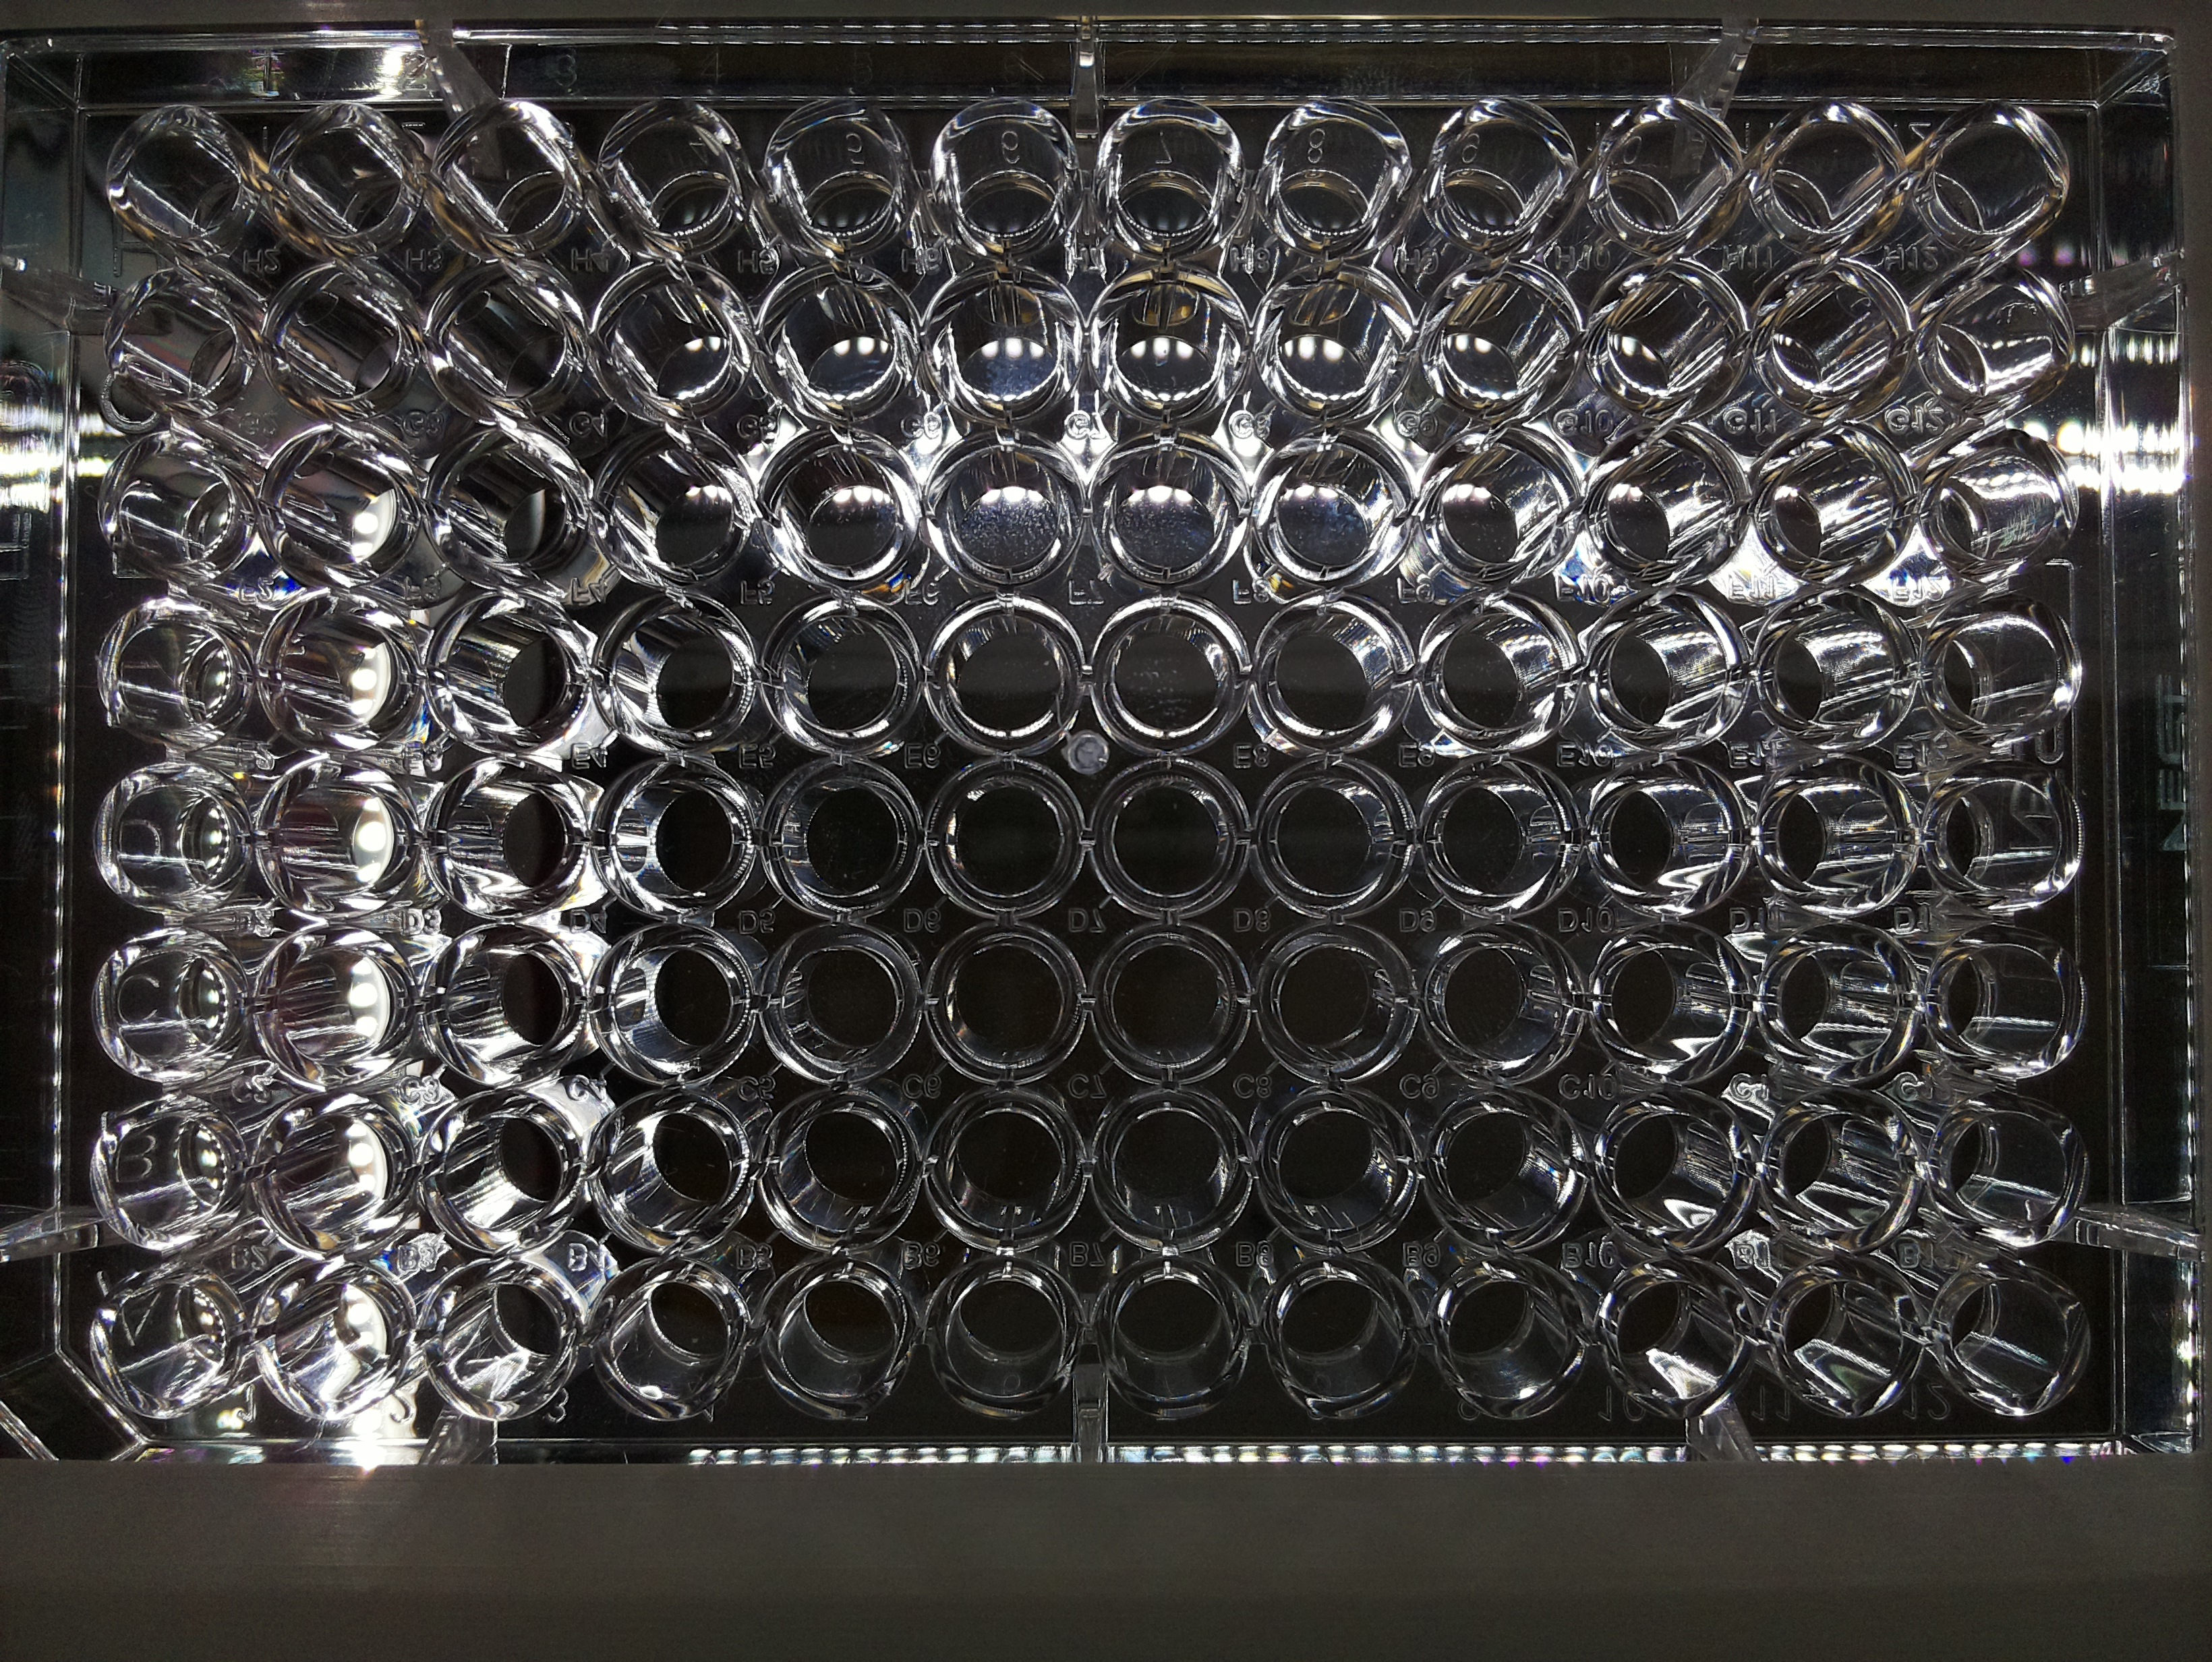

Image captured
Image saved as captured_image.jpg
None


In [2]:
async def capture_photo():
    uri = "ws://172.28.236.86:8765"
    
    async with websockets.connect(uri, max_size=5_000_000) as websocket:
        # send command to capture
        await websocket.send("capture")
        
        # wait for response
        response = await websocket.recv()
        
        try:
            # decode from Base64
            img_data = base64.b64decode(response)
            
            display(IPythonImage(data=img_data, format='jpg'))
            print("Image captured")

            with open("captured_image.jpg", "wb") as f:
                f.write(img_data)
            print("Image saved as captured_image.jpg")

        except Exception as e:
            print("Response:", response)
            print("Exception:", e)

result = await capture_photo()
print(result)

## Overlay Contour on Image for Visualization

In [3]:
image_path = 'captured_image.jpg'
#image_path = 'empty_wells.jpg'
#image_path = 'two_wells_samples.jpg'

In [4]:
def load_image(image_path):
    # Load and convert the image to RGB if not already in that mode
    image = PILImage.open(image_path).convert("RGB")
    return image

def display_image_with_pixel_value(image_path, x, y):
    # Load the image
    image = load_image(image_path)
    # Convert image to array for display purposes
    image_array = np.array(image)
    # Get the RGB value at the selected coordinates
    rgb_value = image.getpixel((x, y))
    # Create a copy of the image to draw the red dot
    draw = ImageDraw.Draw(image)
    dot_radius = 5
    draw.ellipse((x - dot_radius, y - dot_radius, x + dot_radius, y + dot_radius), fill='red', outline='red')
    # Display the image with the red dot
    plt.figure(figsize=(6,6))  # Optional: Set figure size
    plt.imshow(image)
    plt.axis('on')
    plt.title(f'RGB value at ({x}, {y}): {rgb_value}')

image = load_image(image_path)
width, height = image.size
# Create interactive sliders for x and y coordinates
interact(display_image_with_pixel_value,
         image_path=fixed(image_path),
         x=IntSlider(min=0, max=width-1, step=1, value=width//2),
         y=IntSlider(min=0, max=height-1, step=1, value=height//2))

interactive(children=(IntSlider(value=1640, description='x', max=3279), IntSlider(value=1232, description='y',…

<function __main__.display_image_with_pixel_value(image_path, x, y)>

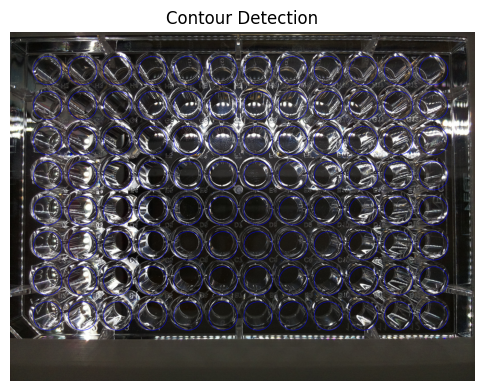

In [5]:
# parameters for bilateral filtering
diameter = 5
sigmaColor = 75
sigmaSpace = 75

image_gray = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
filtered_image = cv2.bilateralFilter(image_gray, diameter, sigmaColor, sigmaSpace)
image_rgb = cv2.imread(image_path)

rows = 8
cols = 12

# define coordinates for top-left and bottom-right grid points
top_left = (265, 278)
bottom_right = (2989, 2006)

x_step = (bottom_right[0] - top_left[0]) / (cols - 1)
y_step = (bottom_right[1] - top_left[1]) / (rows - 1)

expected_grid = []
rgb_values = []

for row in range(rows):
    for col in range(cols):
        x = int(top_left[0] + col * x_step)
        y = int(top_left[1] + row * y_step)
        expected_grid.append((x, y))
        
        # image[row, col] → image[y, x]
        b, g, r = image_rgb[y, x]  
        rgb_values.append([r, g, b]) 

output_grid = image_rgb.copy()

# draw circle
for (x, y) in expected_grid:
    cv2.circle(output_grid, (x, y), 100, (255, 0, 0), 2)

output_grid_rgb = cv2.cvtColor(output_grid, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(output_grid_rgb)
plt.axis("off")
plt.title("Contour Detection")
plt.show()

## Plot of Background Colors

1st well: [105, 99, 103]
2nd well: [193, 198, 194]


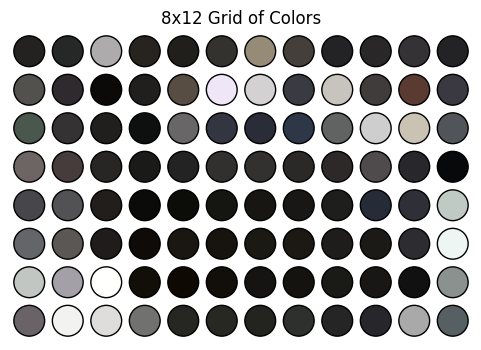

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))

# make sure to have exact number of rows and columns
if len(rgb_values) < rows * cols:
    rgb_values += [[0, 0, 0]] * (rows * cols - len(rgb_values))

for row in range(rows):
    for col in range(cols):
        index = row * cols + col
        rgb = rgb_values[index]
        # normalize RGB values to [0, 1]
        color = [val / 255 for val in rgb]
        # note the y-coordinate is inverted for display.
        circle = plt.Circle((col + 0.5, rows - row - 0.5), 0.4, facecolor=color, 
                            edgecolor='black', linewidth=1)
        ax.add_patch(circle)

print('1st well:', rgb_values[84])
print('2nd well:', rgb_values[72])

ax.set_xlim(0, cols)
ax.set_ylim(0, rows)
ax.set_aspect('equal')
ax.axis('off') 
plt.title('8x12 Grid of Colors')
plt.show()

## LHS

In [33]:
def latin_hypercube_sum_constraint(n_samples, n_variables, sum_constraint,seed):
    # generate Latin Hypercube samples
    if seed is not None:
        np.random.seed(seed)
    lhs_samples = lhs(n_variables, samples=n_samples, criterion='maximin')
    #sampling = LHS(xlimits=xlimits,random_state = np.random.RandomState(0))

    # transform samples to satisfy sum constraint
    for i in range(n_samples):
        current_sum = np.sum(lhs_samples[i, :])
        lhs_samples[i, :] *= sum_constraint / current_sum

    return lhs_samples

# seeds = [1,2,3,4,5]
seeds = [1]
arrays = []
n_samples = 4

for seed in seeds:
    df_lhs = pd.DataFrame(
        latin_hypercube_sum_constraint(
            n_samples=n_samples,
            n_variables=4,
            sum_constraint=270.0,
            seed=seed
        ),
        columns=["C", "M", "Y", "K"],
    )
    arrays.append(df_lhs.to_numpy().T)

CMYK_values = []

for i, array in enumerate(arrays):
    seed_value = seeds[i]
    
    c_values_str = ", ".join(map(str, array[0]))
    m_values_str = ", ".join(map(str, array[1]))
    y_values_str = ", ".join(map(str, array[2]))
    k_values_str = ", ".join(map(str, array[3]))

    print(f"Results for seed {seed_value}:")
    print("C (blue) values:")
    print(c_values_str)
    print("\nM (red) values:")
    print(m_values_str)
    print("\nY (yellow) values:")
    print(y_values_str)
    print("\nK (black) values:")
    print(k_values_str)
   # print("\n" + "-"*50 + "\n")

    CMYK_values.append({
        "Results for seed": seed_value,
        "C (blue) values": c_values_str,
        "M (red) values": m_values_str,
        "Y (yellow) values": y_values_str,
        "K (black) values": k_values_str
    })

with open("CMYK_values.json", "w") as f:
    json.dump(CMYK_values, f, indent=2)

Results for seed 1:
C (blue) values:
71.05809443170705, 83.86700699218619, 4.506169411300044, 48.14905083668657

M (red) values:
55.912295139203444, 29.315613295486525, 151.3898373145717, 85.17266010030099

Y (yellow) values:
56.95880807134397, 114.66529822858064, 89.51441943891615, 5.309367365920778

K (black) values:
86.07080235774558, 42.15208148374661, 24.58957383521207, 131.36892169709168


## Run Opentron

In [ ]:
import sys
# !{sys.executable} -m pip install opentrons
# !pip install opentrons
## Imports
from opentrons import protocol_api, execute, simulate
from opentrons.types import Location, Point
import pandas as pd
import numpy as np

#from opentrons import containers, instruments
# protocol = simulate.get_protocol_api('2.10')
protocol = execute.get_protocol_api('2.19')

#Arthur added this
#protocol = execute.get_protocol_api("2.19")
#protocol.home()

In [ ]:
# function for moving liquid since repetitive
def pipette_action(protocol, pipette, stock_volume_to_pull, stock_position_to_pull, destination_well,stockname):
    pipette.aspirate(stock_volume_to_pull, stock_position_to_pull)
    pipette.dispense(stock_volume_to_pull, destination_well)
    pipette.touch_tip()  
    #pipette.blow_out(destination_well)

def stock_in_all(stock,stock_location,tip_max_vol,dis_tray,name):
    '''
    Args- 
    stock: 1D array of all the stock volumes
    stock_location: 1D array of the stock locations corresponding to volumes
    tip_max_vol: float num of the max volume tip can hold
    dis_tray: 1D array of all the locaitons for dispensing
    name: stock name str

    Function-
    Determine the number of times needed to get stock and dispence. 
    If the volume is larger than the tip can hold, automatically determined how many times it has to aspirate and dispence. 
    Care since stock, stock_location, dis_tray are all arrays
    '''
#     i = 0
    for i in range(len(stock)):
        stock_amount = stock[i]
        if stock_amount == 0:
            pass
        elif stock[i] >= tip_max_vol: # eg:300 is max tip volume
            n = stock[i]//tip_max_vol
            if n > 0: 
                for count in range(int(n)):
                    pipette_action(protocol, 
                            pipette = pip, 
                            stock_volume_to_pull = tip_max_vol, 
                            stock_position_to_pull = stock_location[i], 
                            destination_well = dis_tray[i],
                            stockname= name )
                    stock_amount -= tip_max_vol
                    
                    if stock_amount <= stock[i] - tip_max_vol*n and stock_amount != 0:
                        pipette_action(protocol, 
                                    pipette = pip, 
                                    stock_volume_to_pull = (stock[i] - tip_max_vol*n),
                                    stock_position_to_pull = stock_location[i], 
                                    destination_well = dis_tray[i],
                                    stockname= name )
        else: 
            pipette_action(protocol, 
                           pipette = pip, 
                           stock_volume_to_pull = stock[i], 
                           stock_position_to_pull = stock_location[i], 
                           destination_well = dis_tray[i],
                           stockname= name )
def loc_stock(n_samples,fill):
    array = []
    #fill array
    for i in range(n_samples): 
        array.append(fill) 
    return array

def loc_mixing(start,n_sample): 
    array = []
    for i in range(n_sample):
        array.append(plate.wells()[i+start].top(z = 85)) # Change elevation here using top(z=90)
#         array.append(plate.wells()[i+start].center())
    return array

In [ ]:
## pipette and labware
tiprack = protocol.load_labware('opentrons_96_tiprack_300ul', '6')
pip = protocol.load_instrument('p300_single_gen2', 'right', tip_racks=[tiprack])
stock = protocol.load_labware('corning_6_wellplate_16.8ml_flat',location='3')
stock2 = protocol.load_labware('corning_6_wellplate_16.8ml_flat',location='2')
plate = protocol.load_labware('opentrons_96_wellplate_200ul_pcr_full_skirt','1')
# plate.set_offset(x=0, y=0, z=.5)
plate.set_offset(x=0, y=0, z=33)
start_stock = {
    'magenta_loc': [stock.wells()[0].center(),stock.wells()[1].center()],#stock.wells()[0].center()
    #'water_loc': loc_stock(3,stock.wells()[0].center())+loc_stock(3,stock.wells()[1].center()),#stock.wells()[0].center()
    'magenta_vol':[20000,20000] ,# adjust the volumes for each(6) concentration
    'cyan_loc':[stock.wells()[2].center(),stock.wells()[3].center()], #stock.wells()[1].center()
    #'dmf_loc':loc_stock(3,stock.wells()[2].center())+loc_stock(3,stock.wells()[3].center()), #stock.wells()[1].center()
    'cyan_vol':[20000,20000],# adjust the volumes for each(6) concentration
    'yellow_loc':[stock.wells()[4].center(),stock.wells()[5].center()],#stock.wells()[2].center()
    #'ethanol_loc':loc_stock(3,stock.wells()[4].center())+loc_stock(3,stock.wells()[5].center()),#stock.wells()[2].center()
    'yellow_vol':[20000,20000],# adjust the volumes for each(6) concentration
    'black_loc':[stock2.wells()[0].center(),stock2.wells()[1].center()],#stock.wells()[2].center()
    #'ethanol_loc':loc_stock(3,stock.wells()[4].center())+loc_stock(3,stock.wells()[5].center()),#stock.wells()[2].center()
    'black_vol':[20000,20000]# adjust the volumes for each(6) concentration
}
start_stock = pd.DataFrame(data=start_stock)

##Calling the function
# N_samples = 96

# number of samples should be increasing
# -------------------------------------------------------------
N_samples = 1

loc_red_stoc = loc_stock(N_samples,start_stock['magenta_loc'][0])
loc_blue_stoc = loc_stock(N_samples,start_stock['cyan_loc'][0])
loc_yellow_stoc = loc_stock(N_samples,start_stock['yellow_loc'][0])
loc_black_stoc = loc_stock(N_samples,start_stock['black_loc'][0])

loc_mixing = loc_mixing(0, N_samples) #Start is 0 - 95, A: 0-11, B: 12-23, 
loc_mixing

In [ ]:
# RGB_stocksandlocations = {
#     'mix_loc': loc_mixing,  # Note: loc_mixing needs to be handled separately
#     'stock_red_vol': [77.44581101551692, 11.546358436565134, 78.69476237106129, 133.92480929691936, 23.45725442511232, 34.214508151236785, 80.65295720413329, 102.90089286630496
#                      ],
#     'stock_blue_vol': [93.01478492294865, 148.52689122118792, 46.77838891842151, 30.08010518248808, 6.222927761134619, 79.06778736672267, 48.64187592001704, 106.36728416140619
#                       ],
#     'stock_yellow_vol': [37.24451914443951, 49.84456756420468, 72.45247741260627, 2.116495407929885, 104.2715869005695, 89.11625704033183, 86.33764924205805, 55.55365548974068
#                         ],
#     'stock_black_vol': [62.29488491709496, 60.08218277804225, 72.07437129791093, 103.87859011266265, 136.04823091318354, 67.60144744170866, 54.36751763379163, 5.178167482548181
#                        ]
# }

RGB_stocksandlocations = {
    'mix_loc': loc_mixing,  # Note: loc_mixing needs to be handled separately
    'stock_red_vol': [m_values_str],
    'stock_blue_vol': [c_values_str],
    'stock_yellow_vol': [y_values_str],
    'stock_black_vol': [k_values_str]
}

# Verify lengths of all columns
print("Length of mix_loc:", len(loc_mixing))  # Replace 'loc_mixing' with actual data or a placeholder
print("Length of stock_red_vol:", len(RGB_stocksandlocations['stock_red_vol']))
print("Length of stock_blue_vol:", len(RGB_stocksandlocations['stock_blue_vol']))
print("Length of stock_yellow_vol:", len(RGB_stocksandlocations['stock_yellow_vol']))


# Create a DataFrame
RGB_stocks = pd.DataFrame(RGB_stocksandlocations)

# Show the first few rows
RGB_stocks.head()

red_stock_vol    = pd.Series.to_list(RGB_stocks['stock_red_vol'])
blue_stock_vol   = pd.Series.to_list(RGB_stocks['stock_blue_vol'])
yellow_stock_vol = pd.Series.to_list(RGB_stocks['stock_yellow_vol'])
black_stock_vol = pd.Series.to_list(RGB_stocks['stock_black_vol'])

red_stock_loc   = start_stock['magenta_loc'][0]
blue_stock_loc    = start_stock['cyan_loc'][0]
yellow_stock_loc = start_stock['yellow_loc'][0]
black_stock_loc = start_stock['black_loc'][0]

dispense = pd.Series.to_list(RGB_stocks['mix_loc'])

In [ ]:
## commands
protocol.home()
pip.transfer(red_stock_vol,red_stock_loc ,dispense,blow_out=True,blowout_location="destination well" ,new_tip='once',trash = False)
# pip.drop_tip()
# move blue 
pip.transfer(blue_stock_vol,blue_stock_loc ,dispense,blow_out=True,blowout_location="destination well" ,new_tip='once',trash = False) 
# pip.drop_tip()
# # move yellow
pip.transfer(yellow_stock_vol,yellow_stock_loc,dispense,blow_out=True,blowout_location="destination well",new_tip='once',trash = False) 
# pip.drop_tip()
# move black
pip.transfer(black_stock_vol,black_stock_loc,dispense,blow_out=True,blowout_location="destination well",new_tip='once',trash = False) 
protocol.home()

for line in protocol.commands(): 
    print(line)

#for i in range(1,len(dispense)+1):
    #pip.mix(3, 100, plate[let+str(i)])   # mix 3 times, 100uL, in all plates 

## Recapture Picture

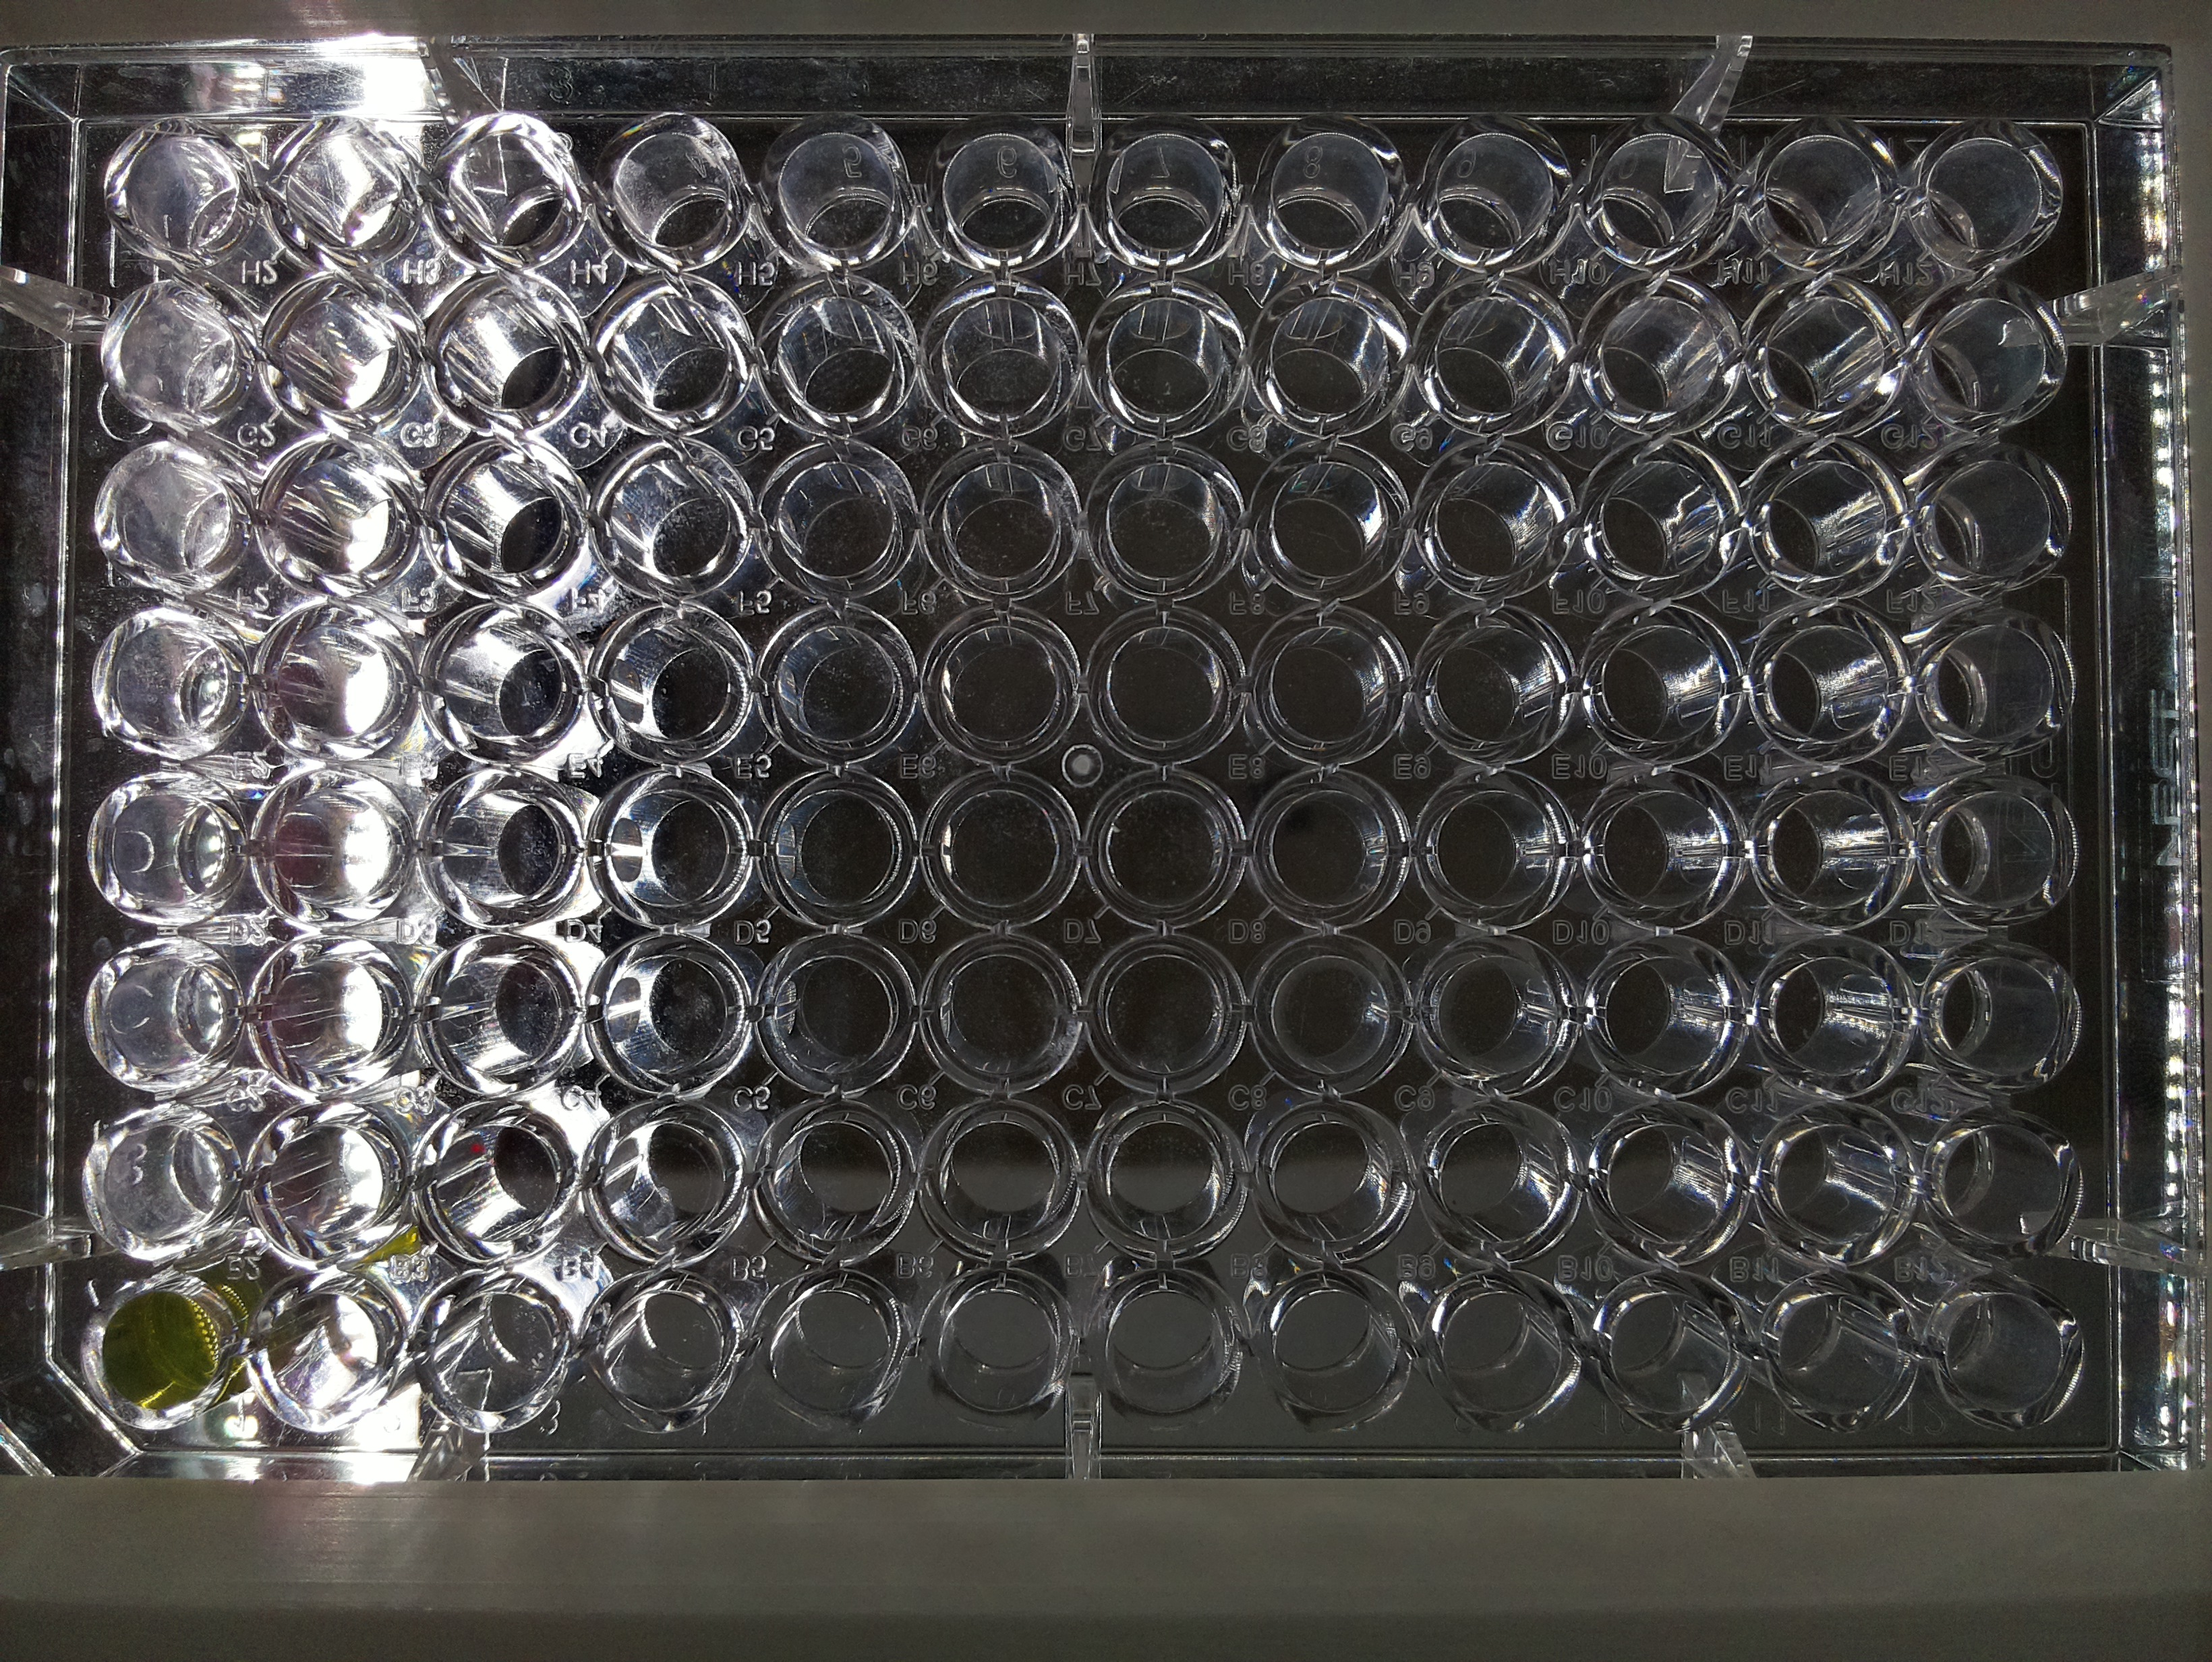

Image captured
Image saved as captured_image.jpg
None


In [35]:
result = await capture_photo()
print(result)

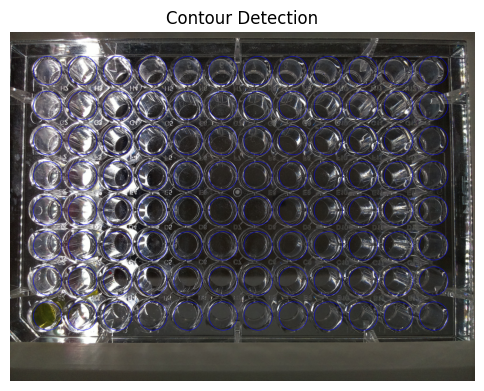

In [50]:
#image_path = 'captured_image.jpg'
image_path = 'one_well_sample.jpg'

# parameters for bilateral filtering
diameter = 5
sigmaColor = 75
sigmaSpace = 75

image_gray = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
filtered_image = cv2.bilateralFilter(image_gray, diameter, sigmaColor, sigmaSpace)
image_rgb = cv2.imread(image_path)

rows = 8
cols = 12

# define coordinates for top-left and bottom-right grid points
top_left = (265, 278)
bottom_right = (2989, 2006)

x_step = (bottom_right[0] - top_left[0]) / (cols - 1)
y_step = (bottom_right[1] - top_left[1]) / (rows - 1)

expected_grid = []
new_rgb_values = []

for row in range(rows):
    for col in range(cols):
        x = int(top_left[0] + col * x_step)
        y = int(top_left[1] + row * y_step)
        expected_grid.append((x, y))
        
        # image[row, col] → image[y, x]
        b, g, r = image_rgb[y, x]  
        new_rgb_values.append([r, g, b]) 

output_grid = image_rgb.copy()

# draw circle
for (x, y) in expected_grid:
    cv2.circle(output_grid, (x, y), 100, (255, 0, 0), 2)

output_grid_rgb = cv2.cvtColor(output_grid, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(output_grid_rgb)
plt.axis("off")
plt.title("Contour Detection")
plt.show()

[52, 58, 12]


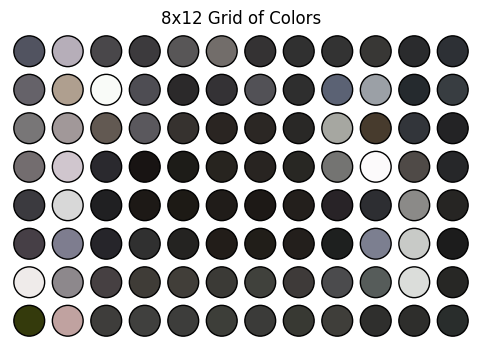

In [64]:
fig, ax = plt.subplots(figsize=(6, 4))

# make sure to have exact number of rows and columns
if len(rgb_values) < rows * cols:
    new_rgb_values += [[0, 0, 0]] * (rows * cols - len(new_rgb_values))

for row in range(rows):
    for col in range(cols):
        index = row * cols + col
        rgb = new_rgb_values[index]
        # normalize RGB values to [0, 1]
        color = [val / 255 for val in rgb]
        # note the y-coordinate is inverted for display.
        circle = plt.Circle((col + 0.5, rows - row - 0.5), 0.4, facecolor=color, 
                            edgecolor='black', linewidth=1)
        ax.add_patch(circle)

print(new_rgb_values[84])

# print(rgb_values)
ax.set_xlim(0, cols)
ax.set_ylim(0, rows)
ax.set_aspect('equal')
ax.axis('off') 
plt.title('8x12 Grid of Colors')
plt.show()

# Optimization

## Plot of Sampled RGB

Changed grid cells (index, background RGB, new RGB, diff):
(0, [83, 85, 98], [81, 83, 96], 439.9409051224948)
(2, [97, 97, 97], [73, 71, 74], 401.2642520833372)
(6, [67, 68, 70], [52, 50, 51], 413.393275223485)
(11, [48, 51, 56], [45, 48, 53], 438.20885431492593)
(12, [110, 105, 111], [101, 98, 105], 430.70871827721345)
(14, [253, 255, 252], [249, 251, 248], 436.4768035073571)
(16, [47, 47, 45], [43, 41, 42], 435.9048061217036)
(24, [122, 121, 126], [120, 118, 119], 436.4928407202116)
(38, [62, 62, 64], [42, 41, 46], 409.34704102997983)
(39, [38, 37, 35], [24, 20, 19], 416.2751493904002)
(41, [40, 37, 32], [39, 36, 31], 441.6729559300637)
(43, [45, 42, 37], [40, 39, 35], 437.6368357439762)
(50, [37, 37, 39], [32, 32, 34], 434.7447526997882)
(51, [32, 28, 27], [29, 25, 22], 437.057204493874)
(52, [31, 31, 23], [29, 26, 21], 438.21570031207233)
(54, [31, 28, 23], [29, 25, 22], 439.9431781491787)
(55, [36, 37, 31], [35, 31, 28], 437.6459756469834)
(59, [47, 47, 45], [38, 37, 35], 426.6626

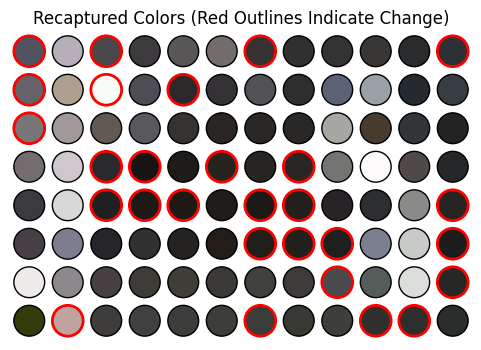

In [ ]:
# Extract the new grid of RGB values using the same grid positions
for row in range(rows):
    for col in range(cols):
        x = int(top_left[0] + col * x_step)
        y = int(top_left[1] + row * y_step)
        b, g, r = new_image_rgb[y, x]
        new_rgb_values.append([r, g, b])

# Define a threshold (in the same RGB scale) for detecting a significant color change.
threshold = 400

# Compare the new colors with the background colors
changed_cells = []  # list to store indices and differences
for idx, (bg_color, new_color) in enumerate(zip(rgb_values, new_rgb_values)):
    diff = np.linalg.norm(np.array(new_color) - np.array(bg_color))
    if diff > threshold:
        changed_cells.append((idx, bg_color, new_color, diff))

# Report the changes
print("Changed grid cells (index, background RGB, new RGB, diff):")
for cell in changed_cells:
    print(cell)

# Create a grid visualization of the new image's colors and highlight cells with changes.
fig, ax = plt.subplots(figsize=(6, 4))
for row in range(rows):
    for col in range(cols):
        index = row * cols + col
        new_rgb = new_rgb_values[index]
        color = [val / 255 for val in new_rgb]
        circle = plt.Circle((col + 0.5, rows - row - 0.5), 0.4, facecolor=color,
                            edgecolor='black', linewidth=1)
        ax.add_patch(circle)
        
        # Check if this cell is in the changed list; if yes, overlay a red outline.
        diff = np.linalg.norm(np.array(new_rgb) - np.array(rgb_values[index]))
        if diff > threshold:
            highlight = plt.Circle((col + 0.5, rows - row - 0.5), 0.4, fill=False,
                                   edgecolor='red', linewidth=2)
            ax.add_patch(highlight)
            
ax.set_xlim(0, cols)
ax.set_ylim(0, rows)
ax.set_aspect('equal')
ax.axis('off')
plt.title('Recaptured Colors (Red Outlines Indicate Change)')
plt.show()

## Converge BO

In [121]:
from pyDOE import lhs
from smt.sampling_methods import LHS
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial import distance

import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C
from scipy.optimize import minimize
from scipy.stats import norm

def RGB_to_CMYK(RGB_sample):

    Red = RGB_sample[0]
    Green = RGB_sample[1]
    Blue = RGB_sample[2]

    Black = min(1-Red,1-Green,1-Blue)
    Cyan = (1-Red-Black)/(1-Black)
    Magenta = (1-Green-Black)/(1-Black)
    Yellow  = (1-Blue-Black)/(1-Black) 

    return np.array([Cyan, Magenta, Yellow, Black])

n_samples = 6
max_well_volume = 270
seed = np.random.seed(1)

max_RGB = 255
target_color = [75, 46, 131]
target_color_norm_RGB = np.array(target_color)/max_RGB
target_color_norm_CMYK = RGB_to_CMYK(target_color_norm_RGB)

# using CMYK value of the first sample
sample_CMYK_norm = np.array([(10, 0, 100, 77)]) / max_well_volume

# Optimization Parameters
hyperparameter = 0.01
threshold = 0.025
max_iterations = 20

# Initialize variables
np.random.seed(41)
n_features = 4  # CMYK components
bounds = [(0, 1)] * n_features  # CMYK values are normalized between 0 and 1

# Randomly initialize samples and their corresponding scores
X = sample_CMYK_norm  # Initial mixtures (inputs)
y = -np.linalg.norm(X - target_color_norm_CMYK, axis=1)  # Objective: minimize distance to target color

# Gaussian Process Regression model
kernel = C(constant_value=1, constant_value_bounds=(1e-3, 1e3)) * RBF(length_scale=1, length_scale_bounds=(1e-3, 1e3))
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10, alpha=1e-4, normalize_y=False)

In [117]:
# https://ekamperi.github.io/machine%20learning/2021/06/11/acquisition-functions.html

# Expected Improvement maximizes implicetly
def expected_improvement(X, X_sample, y_sample, model):
    """Return the expected improvement.
    Arguments
    mu     -- The predictive mean at the test points.
    sigma -- The predictive standard deviation at
             the test points.
    ymax  -- The maximum observed value (so far).
    """
    mu, sigma = model.predict(X, return_std=True)
    '''No noise is causing sigma to approach 0'''

    optiminal_sample = np.min(y_sample)
    
    with np.errstate(divide="ignore"):
        
        imp = mu - optiminal_sample - hyperparameter
        Z = imp / sigma
        ei = imp * norm.cdf(Z) + sigma * norm.pdf(Z)
        ei[sigma == 0.0] = 0.0
    return ei.flatten()

# Function to propose the next sample point using Expected Improvement
def propose_location(acquisition, X_sample, y_sample, bounds, n_restarts=25):
    dim = X_sample.shape[1]

    def min_obj(x):
        return -acquisition(x.reshape(-1, dim), X_sample, y_sample, gp)

    # Starting points for optimization
    x0_list = np.random.uniform(0, 1, size=(n_restarts, dim))
    best_x, best_val = None, float("inf")
    for x0 in x0_list:
        res = minimize(min_obj, x0, bounds=bounds, method="L-BFGS-B")
        if res.fun < best_val:
            best_val = res.fun
            best_x = res.x
    return best_x

In [ ]:
# Run Bayesian Optimization and visualize

distances = []  # Track distances to the target
X_samples = []  # Start with the first sample

for i in range(max_iterations):
    gp.fit(X, y)  # Fit GP model
    
    # Propose the next sampling point
    X_next = propose_location(expected_improvement, X, y, bounds)
    
    # Evaluate the objective function for the new sample
    y_next = -np.linalg.norm(X_next - target_color_norm_CMYK)
    distances.append(-y_next)  # Track the negative distance (closer to target)
    
    # Append the new sample to the dataset
    X = np.vstack((X, X_next))
    y = np.append(y, y_next)
    
    # Track the selected color
    X_samples.append(X_next)

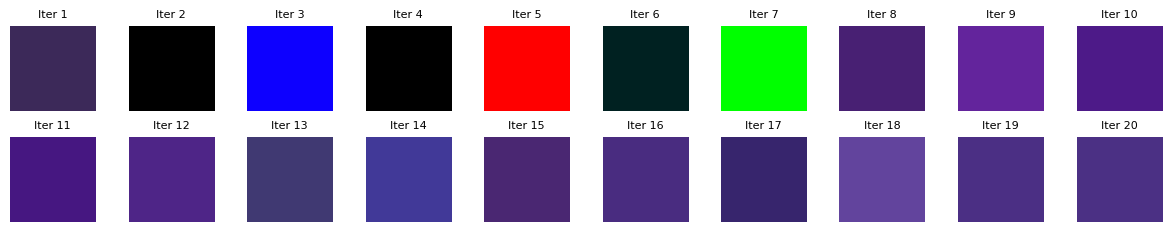

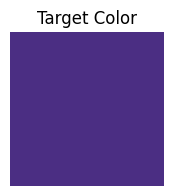

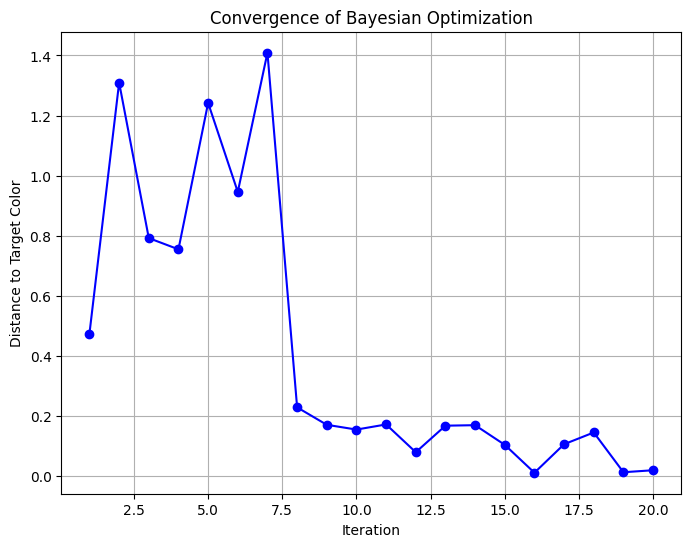

Closest distance to target color: 0.011776465345624416
Optimal CMYK mixture: [0.4262779  0.65299693 0.         0.4972327 ]
Target CMYK mixture: [0.29411765 0.18039216 0.51372549]


In [119]:
# Visualization of selected colors
def CMYK_to_RGB(cyan_percent, magenta_percent, yellow_percent, black_percent):
    
    R = (1 - cyan_percent) * (1-black_percent)
    G = (1 - magenta_percent) * (1-black_percent)
    B = (1 - yellow_percent) * (1-black_percent)

    return np.array(list(zip(R,G,B)))

def visualize_color_selection(X_samples, target_color):
    """
    Visualize the color combinations chosen by the algorithm over iterations.
    Display colors in a grid with 10 colors per row.
    """
    n_samples = len(X_samples)
    colors_per_row = 10  # Limit to 10 colors per row
    n_rows = (n_samples + colors_per_row - 1) // colors_per_row  # Calculate total rows

    plt.figure(figsize=(12, n_rows * 1.2))
    for idx, rgb in enumerate(X_samples):
        row = idx // colors_per_row
        col = idx % colors_per_row

        # Each color is displayed in its own grid
        plt.subplot(n_rows, colors_per_row, idx + 1)
        plt.imshow([[rgb]], extent=[0, 1, 0, 1])
        plt.axis("off")
        plt.title(f"Iter {idx + 1}", fontsize=8)

    plt.tight_layout()
    
    # Show target color for reference
    plt.figure(figsize=(2, 2))
    plt.imshow([[target_color]], extent=[0, 1, 0, 1])
    plt.axis("off")
    plt.title("Target Color", fontsize=12)
    plt.show()

def column(matrix, i):
    return np.array([row[i] for row in matrix])

X_samples_RGB = CMYK_to_RGB(column(X_samples,0), column(X_samples,1), column(X_samples,2), column(X_samples,3))
#X_samples_RGB = X_samples

# Visualize selected colors
visualize_color_selection(X_samples_RGB, target_color_norm_RGB)

# Plot the convergence
plt.figure(figsize=(8, 6))
plt.plot(range(1, max_iterations + 1), distances, marker='o', linestyle='-', color='b')
plt.title('Convergence of Bayesian Optimization')
plt.xlabel('Iteration')
plt.ylabel('Distance to Target Color')
plt.grid(True)
plt.show()

# Display final results
optimal_rgb = X[np.argmax(y)]
print("Closest distance to target color:", -np.max(y))
print("Optimal CMYK mixture:", optimal_rgb)
print("Target CMYK mixture:", target_color_norm_RGB)

In [138]:
def convert_cmyk_to_dye_amounts(cmyk_percentages, max_volume):
    cmyk_percentages = np.array(cmyk_percentages)  # Ensure it's a NumPy array
    total = np.sum(cmyk_percentages)
    # Normalize to ensure sum is 1 (only if total is nonzero to avoid division by zero)
    if total > 0:
        normalized_cmyk = cmyk_percentages / total
    else:
        normalized_cmyk = np.zeros_like(cmyk_percentages)  # If all zeros, return all zero amounts
    # Scale to maximum volume
    dye_volumes = normalized_cmyk * max_volume
    return dye_volumes

rgb_20th = X_samples_RGB[19] 
print("RGB of the 20th iteration:", rgb_20th*255)

print(convert_cmyk_to_dye_amounts([42,66,0,51], 270))

# note: with RGB values of 73, 43, 126 (20th iteration) --> CMYK of 42, 66, 0, 51 %
# second sample CYMK volume: 71.32075472 112.0754717    0.          86.60377358

RGB of the 20th iteration: [ 75.0403719   48.92882357 132.53781982]
[ 71.32075472 112.0754717    0.          86.60377358]


## RGB to CMYK

In [ ]:
import pandas as pd
import numpy as np

# Convert RGB to CMYK
def rgb_to_cmyk(r, g, b):
    r, g, b = r / 255, g / 255, b / 255  # Normalize RGB
    k = 1 - max(r, g, b)
    if k == 1:
        return 0, 0, 0, 1  # Handle edge case when K=1
    c = (1 - r - k) / (1 - k)
    m = (1 - g - k) / (1 - k)
    y = (1 - b - k) / (1 - k)
    return c, m, y, k

# Map optimized RGB values to CMYK
optimized_cmyk_values = [rgb_to_cmyk(*rgb) for rgb in optimized_rgb_values]

# Normalize CMYK values for feedback weights
optimized_normalized_cmyk = np.array(optimized_cmyk_values)

# Function to generate Latin Hypercube samples with feedback
def latin_hypercube_sum_constraint_feedback(n_samples, n_variables, sum_constraint, seed, feedback_weights):
    np.random.seed(seed)
    samples = np.random.uniform(0, 1, (n_samples, n_variables))
    samples *= sum_constraint / samples.sum(axis=1, keepdims=True)  # Scale to sum_constraint
    weighted_samples = samples * feedback_weights  # Apply feedback weights
    return weighted_samples / weighted_samples.sum(axis=1, keepdims=True) * sum_constraint

# Define LHS parameters
seeds = [2]
arrays = []
n_samples = 96
n_variables = 4  # CMYK
sum_constraint = 270.0

# Define feedback weights (e.g., average normalized CMYK values)
feedback_weights = optimized_normalized_cmyk.mean(axis=0)

# Generate LHS samples with feedback
for seed in seeds:
    lhs_samples = latin_hypercube_sum_constraint_feedback(
        n_samples=n_samples,
        n_variables=n_variables,
        sum_constraint=sum_constraint,
        seed=seed,
        feedback_weights=feedback_weights
    )
    arrays.append(lhs_samples.T)

# Display the arrays
for i, array in enumerate(arrays):
    print(f"Results for seed {seeds[i]}:")
    print("C (cyan) values:")
    print(", ".join(map(str, array[0])))
    print("\nM (magenta) values:")
    print(", ".join(map(str, array[1])))
    print("\nY (yellow) values:")
    print(", ".join(map(str, array[2])))
    print("\nK (black) values:")
    print(", ".join(map(str, array[3])))
    print("\n" + "-" * 50 + "\n")

## Next iteration